In [15]:
#. Atomic Simulation Environment

%pip install ase


Note: you may need to restart the kernel to use updated packages.


In [17]:
from ase.build import fcc111
from ase.visualize import view

# Build a 3 x 3 Pt(111) surface with 4 atomic layers
pt_slab = fcc111(
    "Pt",
    size=(3, 3, 4),
    a=3.92,
    vacuum=12.0,
    periodic=True
)

print("Number of platinum atoms:", len(pt_slab))
print("Cell dimensions:")
print(pt_slab.cell)
print("Atomic positions:")
print(pt_slab.get_positions())

Number of platinum atoms: 36
Cell dimensions:
Cell([[8.3155757467538, 0.0, 0.0], [4.1577878733769, 7.201499843782543, 0.0], [0.0, 0.0, 30.78963916567]])
Atomic positions:
[[ 0.00000000e+00  0.00000000e+00  1.20000000e+01]
 [ 2.77185858e+00  0.00000000e+00  1.20000000e+01]
 [ 5.54371716e+00  0.00000000e+00  1.20000000e+01]
 [ 1.38592929e+00  2.40049995e+00  1.20000000e+01]
 [ 4.15778787e+00  2.40049995e+00  1.20000000e+01]
 [ 6.92964646e+00  2.40049995e+00  1.20000000e+01]
 [ 2.77185858e+00  4.80099990e+00  1.20000000e+01]
 [ 5.54371716e+00  4.80099990e+00  1.20000000e+01]
 [ 8.31557575e+00  4.80099990e+00  1.20000000e+01]
 [ 1.38592929e+00  8.00166649e-01  1.42632131e+01]
 [ 4.15778787e+00  8.00166649e-01  1.42632131e+01]
 [ 6.92964646e+00  8.00166649e-01  1.42632131e+01]
 [ 2.77185858e+00  3.20066660e+00  1.42632131e+01]
 [ 5.54371716e+00  3.20066660e+00  1.42632131e+01]
 [ 8.31557575e+00  3.20066660e+00  1.42632131e+01]
 [ 4.15778787e+00  5.60116655e+00  1.42632131e+01]
 [ 6.92964646

In [ ]:
from ase.visualize import view

view(pt_slab)

<Popen: returncode: None args: ['/bin/python3.12', '-m', 'ase', 'gui', '-']>

usage: ase [-h] [--version] [-T]
           {help,info,test,gui,db,run,band-structure,build,dimensionality,eos,ulm,find,nebplot,convert,reciprocal,completion,diff,exec}
           ...
ase: error: ModuleNotFoundError: No module named 'tkinter'
To get a full traceback, use: ase -T gui ...


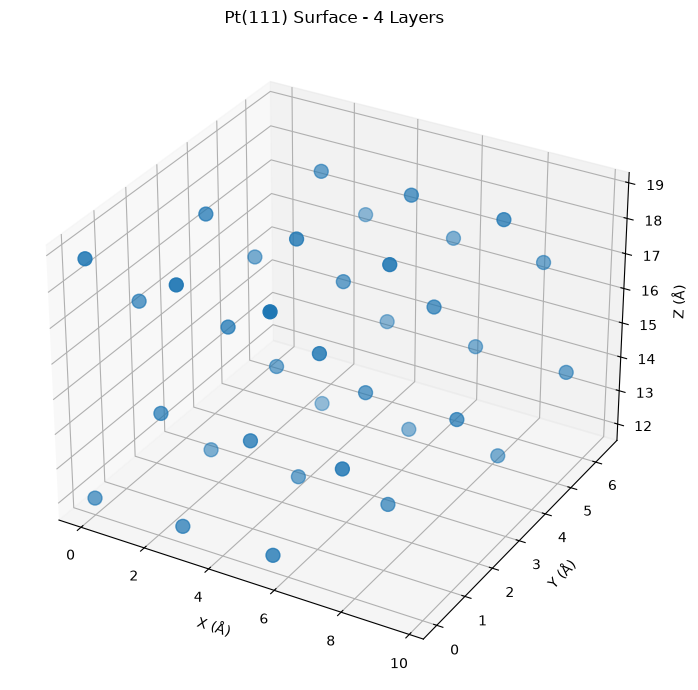

In [19]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

positions = pt_slab.get_positions()

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    positions[:, 0],
    positions[:, 1],
    positions[:, 2],
    s=100,
    label="Platinum atoms"
)

ax.set_xlabel("X (Å)")
ax.set_ylabel("Y (Å)")
ax.set_zlabel("Z (Å)")
ax.set_title("Pt(111) Surface - 4 Layers")

plt.tight_layout()
plt.show()

In [20]:
from ase.build import molecule

# Create water molecule
water = molecule("H2O")

print("Water atoms:", len(water))
print("Atomic symbols:", water.get_chemical_symbols())
print("Atomic positions (Å):")
print(water.get_positions())

Water atoms: 3
Atomic symbols: ['O', 'H', 'H']
Atomic positions (Å):
[[ 0.        0.        0.119262]
 [ 0.        0.763239 -0.477047]
 [ 0.       -0.763239 -0.477047]]


In [21]:
from ase import Atoms
from ase.build import add_adsorbate

# Make a copy of the platinum surface
pt_water = pt_slab.copy()

# Add water above the platinum surface
water_copy = molecule("H2O")

add_adsorbate(
    pt_water,
    water_copy,
    height=2.5,
    position="ontop"
)

print("Total atoms:", len(pt_water))
print("Platinum atoms:", len(pt_slab))
print("Water atoms:", len(water_copy))
print("Atomic symbols:", pt_water.get_chemical_symbols())

Total atoms: 39
Platinum atoms: 36
Water atoms: 3
Atomic symbols: ['Pt', 'Pt', 'Pt', 'Pt', 'Pt', 'Pt', 'Pt', 'Pt', 'Pt', 'Pt', 'Pt', 'Pt', 'Pt', 'Pt', 'Pt', 'Pt', 'Pt', 'Pt', 'Pt', 'Pt', 'Pt', 'Pt', 'Pt', 'Pt', 'Pt', 'Pt', 'Pt', 'Pt', 'Pt', 'Pt', 'Pt', 'Pt', 'Pt', 'Pt', 'Pt', 'Pt', 'O', 'H', 'H']


In [22]:
print("Total atoms:", len(pt_water))
print("Platinum atoms:", sum(
    atom.symbol == "Pt" for atom in pt_water
))
print("Oxygen atoms:", sum(
    atom.symbol == "O" for atom in pt_water
))
print("Hydrogen atoms:", sum(
    atom.symbol == "H" for atom in pt_water
))

Total atoms: 39
Platinum atoms: 36
Oxygen atoms: 1
Hydrogen atoms: 2


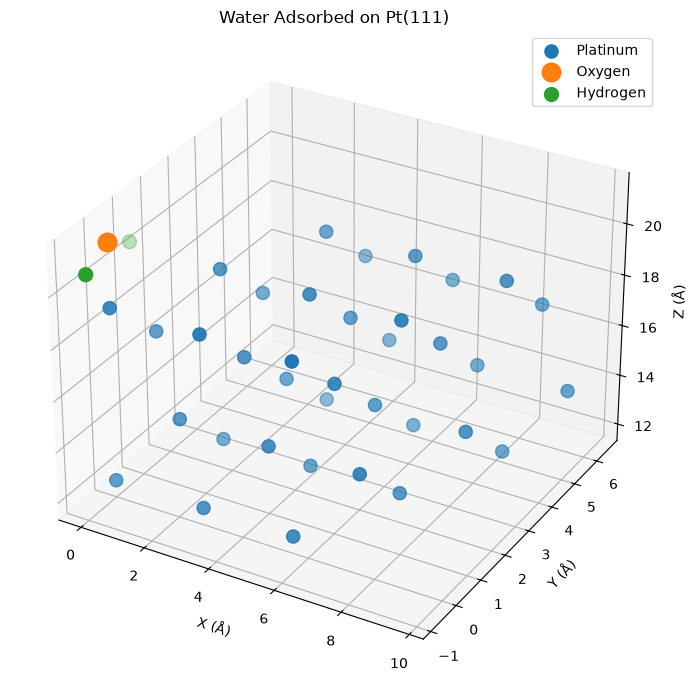

In [23]:
import matplotlib.pyplot as plt

positions = pt_water.get_positions()
symbols = pt_water.get_chemical_symbols()

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

# Plot platinum atoms
pt_indices = [i for i, s in enumerate(symbols) if s == "Pt"]
ax.scatter(
    positions[pt_indices, 0],
    positions[pt_indices, 1],
    positions[pt_indices, 2],
    s=90,
    label="Platinum"
)

# Plot oxygen
o_indices = [i for i, s in enumerate(symbols) if s == "O"]
ax.scatter(
    positions[o_indices, 0],
    positions[o_indices, 1],
    positions[o_indices, 2],
    s=180,
    label="Oxygen"
)

# Plot hydrogen
h_indices = [i for i, s in enumerate(symbols) if s == "H"]
ax.scatter(
    positions[h_indices, 0],
    positions[h_indices, 1],
    positions[h_indices, 2],
    s=100,
    label="Hydrogen"
)

ax.set_xlabel("X (Å)")
ax.set_ylabel("Y (Å)")
ax.set_zlabel("Z (Å)")
ax.set_title("Water Adsorbed on Pt(111)")
ax.legend()

plt.tight_layout()
plt.show()

In [24]:
%pip install gpaw

Note: you may need to restart the kernel to use updated packages.


In [25]:
import gpaw
print("GPAW version:", gpaw.__version__)

GPAW version: 26.7.0


In [26]:
from ase.constraints import FixAtoms

positions = pt_water.get_positions()

# Identify the two bottom platinum layers
z_values = sorted(set(round(z, 3) for z in positions[:36, 2]))
fixed_z = z_values[:2]

# Fix platinum atoms in those layers
fixed_indices = [
    i for i, atom in enumerate(pt_water)
    if atom.symbol == "Pt"
    and round(atom.position[2], 3) in fixed_z
]

pt_water.set_constraint(FixAtoms(indices=fixed_indices))

print("Fixed platinum atoms:", len(fixed_indices))
print("Total atoms:", len(pt_water))

Fixed platinum atoms: 18
Total atoms: 39


In [31]:
from gpaw import GPAW, PW, FermiDirac

calc = GPAW(
    mode=PW(300),
    xc="PBE",
    kpts=(2, 2, 1),
    occupations=FermiDirac(0.1),
    txt="pt_water_dft.txt"
)

pt_water.calc = calc

print("GPAW calculator attached successfully.")

GPAW calculator attached successfully.


In [32]:
print("Cutoff:", pt_water.calc.parameters.mode)
print("K-points:", pt_water.calc.parameters.kpts)

Cutoff: PW(ecut=300.0)
K-points: MonkhorstPack(size=array([2, 2, 1]))


In [33]:
from ase.optimize import BFGS

optimizer = BFGS(
    pt_water,
    trajectory="pt_water_relax_light.traj",
    logfile="pt_water_relax_light.log"
)

optimizer.run(fmax=0.05)

KeyboardInterrupt: 